In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/Mall_Customers.csv")
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [43]:
data['Gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [44]:
data['Gender'] = data['Gender'].replace({'Male':0, 'Female':1})

In [45]:
def chkOutliers(data, column):
    plt.figure(figsize=(7,3))
    plt.subplot(1,2,1)  #row size, column size, plot no
    plt.boxplot(data[column])
    plt.subplot(1,2,2)
    m = data[column].mean()
    std = data[column].std()
    sns.histplot(data[column], kde=True)
    plt.axvline(m, color='green')
    plt.axvline(m - 3 * std, color='red')
    plt.axvline(m + 3 * std, color='red')
    plt.show()

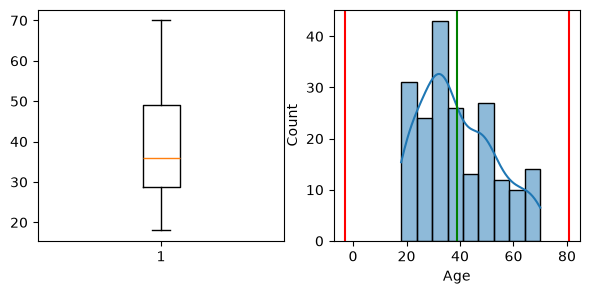

In [46]:
chkOutliers(data, 'Age')

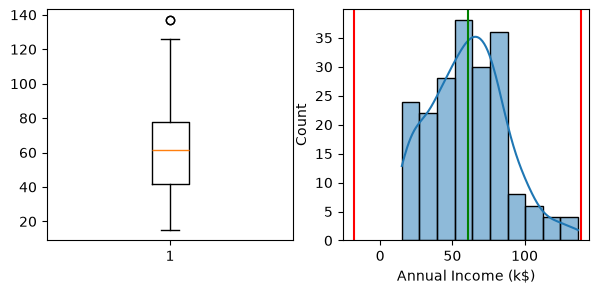

In [47]:
chkOutliers(data, 'Annual Income (k$)')

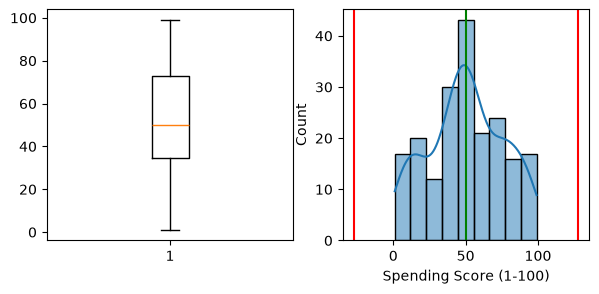

In [48]:
chkOutliers(data, 'Spending Score (1-100)')

In [49]:
def replaceOutliers(data, column):
    q3 = data[column].quantile(0.75)
    q1 = data[column].quantile(0.25)
    iqr = q3 - q1
    ub = q3 + iqr * 1.5
    lb = q1 - iqr * 1.5
    data[column] = data[column].astype(float)
    data.loc[data[column] > ub, column] = ub
    data.loc[data[column] < lb, column] = lb
    

In [50]:
replaceOutliers(data, 'Annual Income (k$)')

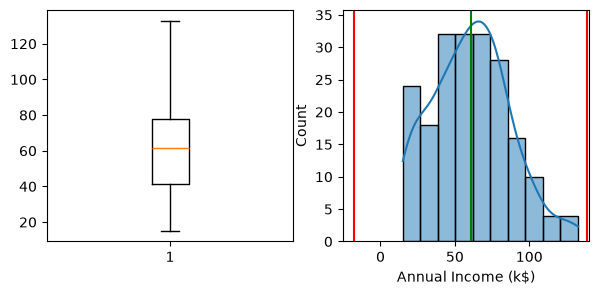

In [51]:
chkOutliers(data, 'Annual Income (k$)')

In [52]:
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15.0,39
1,2,0,21,15.0,81
2,3,1,20,16.0,6
3,4,1,23,16.0,77
4,5,1,31,17.0,40


<Axes: >

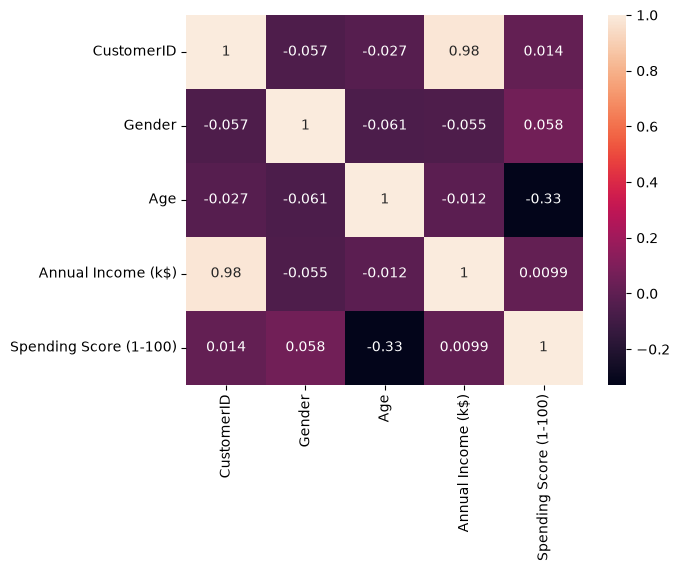

In [53]:
sns.heatmap(data.corr(), annot=True)

In [54]:
X = data.drop('CustomerID', axis=1)

In [55]:
from sklearn.cluster import KMeans

In [56]:
from sklearn.metrics import silhouette_score

In [57]:
k = []
inertia = []
sil_coef = []

for i in range(3, 15):
    km = KMeans(n_clusters=i)
    km.fit(X)
    train_pred = km.predict(X)
    k.append(i)
    inertia.append(km.inertia_)
    sil_coef.append(silhouette_score(X, train_pred))
    

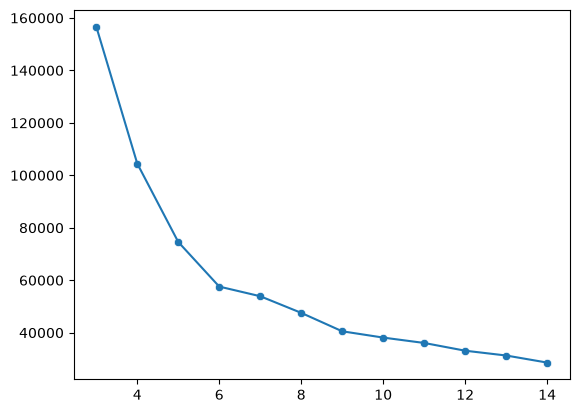

In [58]:
sns.lineplot(x=k, y=inertia)
sns.scatterplot(x=k, y=inertia)
plt.show()

In [59]:
import matplotlib.pyplot as plt

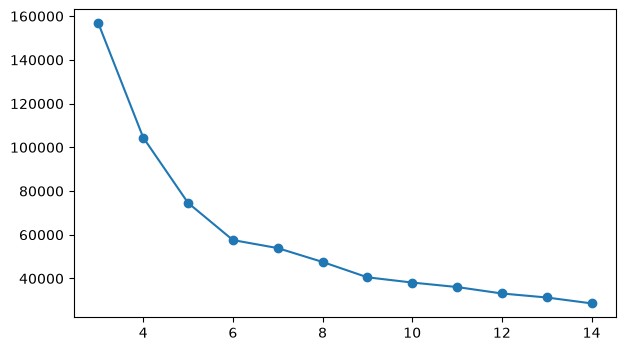

In [60]:
plt.figure(figsize=(7,4))
plt.plot(k, inertia, marker='o')

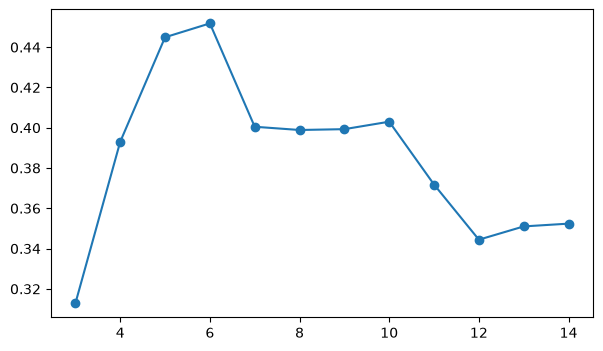

In [61]:
plt.figure(figsize=(7,4))
plt.plot(k, sil_coef, marker='o')

In [62]:
km = KMeans(n_clusters=6)
km.fit(X)
train_pred = km.predict(X)

In [63]:
centers = km.cluster_centers_
centers

array([[ 0.65789474, 27.        , 56.65789474, 49.13157895],
       [ 0.42857143, 41.68571429, 88.10714286, 17.28571429],
       [ 0.53846154, 32.69230769, 86.42948718, 82.12820513],
       [ 0.59090909, 25.27272727, 25.72727273, 79.36363636],
       [ 0.56818182, 56.34090909, 53.70454545, 49.38636364],
       [ 0.59090909, 44.31818182, 25.77272727, 20.27272727]])

In [64]:
km.inertia_

57542.320062393745

In [65]:
silhouette_score(X, train_pred)

0.4532090466086674

In [66]:
X['Label'] = km.labels_

In [67]:
X.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Label
0,0,19,15.0,39,5
1,0,21,15.0,81,3
2,1,20,16.0,6,5
3,1,23,16.0,77,3
4,1,31,17.0,40,5


In [68]:
X.columns

Index(['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)',
       'Label'],
      dtype='str')

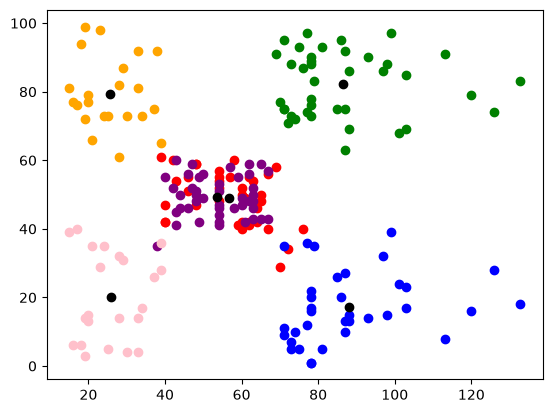

In [69]:
plt.scatter(X[X['Label']==0]['Annual Income (k$)'],
            X[X['Label']==0]['Spending Score (1-100)'], color='red')
plt.scatter(X[X['Label']==1]['Annual Income (k$)'],
            X[X['Label']==1]['Spending Score (1-100)'], color='blue')
plt.scatter(X[X['Label']==2]['Annual Income (k$)'],
            X[X['Label']==2]['Spending Score (1-100)'], color='green')
plt.scatter(X[X['Label']==3]['Annual Income (k$)'],
            X[X['Label']==3]['Spending Score (1-100)'], color='orange')
plt.scatter(X[X['Label']==4]['Annual Income (k$)'],
            X[X['Label']==4]['Spending Score (1-100)'], color='purple')
plt.scatter(X[X['Label']==5]['Annual Income (k$)'],
            X[X['Label']==5]['Spending Score (1-100)'], color='pink')
plt.scatter(centers[:, 2], centers[:,3], color='black')